# Milestone 5: Statistical Analysis
**Kenya retail data platform** · 250,000 transaction lines · Jan 2022 to Sep 2025

This notebook tests the business questions raised in the EDA and SQL milestones. Each test follows the same pattern: **question → hypotheses → assumption checks → test and confidence interval → plain-language conclusion.**

| # | Business question | Method |
|---|---|---|
| 1 | Do M-Pesa transactions have higher average basket values? | Welch t-test, Mann-Whitney, regression check |
| 2 | Did promotions change sales? | Calendar-adjusted regression, difference-in-differences |
| 3 | Do loyalty members spend more? | Welch t-test, Mann-Whitney |
| 4 | Does payday change shopping behaviour? | Welch t-test |
| 5 | Do store types differ in basket value? | ANOVA, Kruskal-Wallis, Tukey |
| 6 | Is payment method linked to sales channel? | Chi-square, Cramér's V |
| 7 | Are promotional sales returned more often? | Two-proportion z-test, Wilson CIs |

**Conventions.** Significance level α = 0.05; all confidence intervals are 95%. Returns are excluded from basket-level tests because they reverse earlier sales rather than record a purchase. The unit of analysis is stated for each test.

**A note on very large samples.** With tens of thousands of invoices, almost any difference is "statistically significant", and normality tests reject for trivial departures. So each test reports an **effect size and confidence interval** next to the p-value, and assumptions are judged mainly from plots, skewness and the central limit theorem rather than from p-values alone.

## Step 1: Import Libraries

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.4f}".format
ALPHA = 0.05
RNG = np.random.default_rng(42)


## Step 2: Load the data sets

In [2]:
DATA = "../data/clean"
tx = pd.read_csv(f"{DATA}/transactions.csv", parse_dates=["transaction_date"])
customers = pd.read_csv(f"{DATA}/customers.csv")
products = pd.read_csv(f"{DATA}/products.csv")
stores = pd.read_csv(f"{DATA}/stores.csv")
promos = pd.read_csv(f"{DATA}/promotions.csv", parse_dates=["start_date", "end_date"])
print(f"{len(tx):,} transaction lines loaded")

250,000 transaction lines loaded


## Step 3: Data Preparation and Statistical Helper Functions

In [3]:
# Separate sales transactions from returns
sales = tx[~tx["is_return"]].copy()

print("Sales transaction lines:", len(sales))
print("Return transaction lines:", tx["is_return"].sum())

# Convert transaction lines into invoice-level data

inv = (
    sales.groupby("invoice_no")
    .agg(
        date=("transaction_date", "min"),
        store_id=("store_id", "first"),
        customer_id=("customer_id", "first"),
        payment=("payment_method", "first"),
        channel=("channel", "first"),

        # True if at least one product in the invoice was on promotion
        on_promo=("on_promo", "max"),

        # True if the invoice occurred during a payday period
        payday=("is_payday_period", "max"),

        # Total value of all products in the invoice
        value=("line_total_kes", "sum"),

        # Total number of units purchased in the invoice
        units=("quantity", "sum")
    )
    .reset_index()
)

print("Number of invoices created:", len(inv))

# Add store information to the invoice dataset
inv = inv.merge(
    stores[["store_id", "store_type"]],
    on="store_id",
    how="left"
)

# Add customer loyalty information
inv = inv.merge(
    customers[["customer_id", "loyalty_member"]],
    on="customer_id",
    how="left"
)

# Create a logarithmic version of invoice value
print(
    "Invoices with zero or negative values:",
    (inv["value"] <= 0).sum()
)

# Calculate the logarithm only for positive invoice values.
inv["log_value"] = np.where(
    inv["value"] > 0,
    np.log(inv["value"]),
    np.nan
)

# Identify M-Pesa invoices
inv["is_mpesa"] = (
    inv["payment"].str.strip().str.lower() == "m-pesa"
)

# Check the prepared invoice dataset
print("\nINVOICE DATA VALIDATION")
print("-----------------------")

print("Total invoices:", len(inv))

print(
    "Duplicate invoice numbers:",
    inv["invoice_no"].duplicated().sum()
)

print(
    "Missing store types:",
    inv["store_type"].isna().sum()
)

print(
    "Missing loyalty information:",
    inv["loyalty_member"].isna().sum()
)

print(
    "Missing payment methods:",
    inv["payment"].isna().sum()
)

print(
    "Zero or negative invoice values:",
    (inv["value"] <= 0).sum()
)

# Examine payment method distribution

print("\nPAYMENT METHOD DISTRIBUTION")

display(
    inv["payment"].value_counts(dropna=False)
)

print("\nM-PESA CLASSIFICATION")

display(
    inv["is_mpesa"].value_counts(dropna=False)
)

# Set up a random number generator
RNG = np.random.default_rng(42)


# Create an empty list for statistical test results
RESULTS = []

# Define Cohen's d effect size function-
# Cohen's d measures the standardised difference between the means of two independent groups.

def cohens_d(a, b):

    # Get the number of observations in each group
    na = len(a)
    nb = len(b)

    # Calculate the pooled standard deviation
    pooled_sd = np.sqrt(
        (
            (na - 1) * a.var(ddof=1)
            + (nb - 1) * b.var(ddof=1)
        ) / (na + nb - 2)
    )

    # Calculate the standardised difference between means
    if pooled_sd == 0:
        return np.nan

    return (a.mean() - b.mean()) / pooled_sd

# Define the probability of superiority function

def prob_superiority(a, b, n=200_000):

    # Convert the input groups into NumPy arrays
    a = np.asarray(a)
    b = np.asarray(b)

    # Randomly select observations from both groups
    ia = RNG.integers(0, len(a), n)
    ib = RNG.integers(0, len(b), n)

    # Calculate the proportion where A is greater than B.
    # Tied values contribute half to the probability.

    return float(
        np.mean(a[ia] > b[ib])
        + 0.5 * np.mean(a[ia] == b[ib])
    )

# Define the bootstrap confidence interval function
def boot_ci(a, b, stat=np.mean, n_boot=2000):

    # Convert both groups into NumPy arrays
    a = np.asarray(a)
    b = np.asarray(b)

    # Store the differences from each bootstrap sample
    differences = []

    # Repeat the sampling process
    for _ in range(n_boot):

        # Draw new samples with replacement
        sample_a = RNG.choice(a, size=len(a), replace=True)
        sample_b = RNG.choice(b, size=len(b), replace=True)

        # Calculate the difference between the two groups
        difference = stat(sample_a) - stat(sample_b)

        differences.append(difference)

    # Calculate the lower and upper limits of the 95% interval
    return np.percentile(differences, [2.5, 97.5])


# Define a function for recording statistical results

def log_result(test, question, p, effect, ci, decision):

    RESULTS.append({
        "Test": test,
        "Question": question,
        "p-value": p,
        "Effect size": effect,
        "95% CI": ci,
        "Decision (alpha = 0.05)": decision
    })

# Display the prepared invoice dataset

print("\nPREPARED INVOICE DATASET")
print("-----------------------")

print(
    f"{len(inv):,} invoices | "
    f"{inv['date'].min().date()} to "
    f"{inv['date'].max().date()}"
)

display(inv.head())

Sales transaction lines: 248708
Return transaction lines: 1292
Number of invoices created: 88543
Invoices with zero or negative values: 0

INVOICE DATA VALIDATION
-----------------------
Total invoices: 88543
Duplicate invoice numbers: 0
Missing store types: 0
Missing loyalty information: 3470
Missing payment methods: 0
Zero or negative invoice values: 0

PAYMENT METHOD DISTRIBUTION


payment
M-Pesa          50651
Cash            25606
Card             8237
Airtel Money     4049
Name: count, dtype: int64


M-PESA CLASSIFICATION


is_mpesa
True     50651
False    37892
Name: count, dtype: int64


PREPARED INVOICE DATASET
-----------------------
88,543 invoices | 2022-01-01 to 2025-09-30


,invoice_no,date,store_id,customer_id,payment,channel,on_promo,payday,value,units,store_type,loyalty_member,log_value,is_mpesa
0,INV100001,2022-01-01,ST018,C2646,Cash,In-store,False,False,"1,287.0000",4,Mini-mart,False,7.1601,False
1,INV100002,2022-01-01,ST028,C1767,Cash,In-store,False,False,"2,386.0000",4,Mini-mart,False,7.7774,False
2,INV100003,2022-01-01,ST037,C0200,M-Pesa,In-store,False,False,477.0000,4,Mini-mart,True,6.1675,True
3,INV100004,2022-01-01,ST018,C2488,M-Pesa,Online,False,False,629.0000,3,Mini-mart,True,6.4441,True
4,INV100005,2022-01-01,ST022,C3062,Cash,In-store,False,False,574.0000,2,Mini-mart,True,6.3526,False


## Test 1: Do M-Pesa customers spend more per basket?
**Unit:** one invoice (basket). **Outcome:** invoice value in KES.

- H₀: mean basket value is the same for M-Pesa and other payment methods.
- H₁: the means differ (two-sided).

**Assumptions to check:** independence (each invoice is a separate purchase), shape of the distribution, equal variances. Invoice values are strongly right-skewed, which is typical for spend data.

M-Pesa: n=50,651, mean=2,472, median=1,947
Other : n=37,892, mean=2,079, median=1,572
Skewness of invoice value: raw=1.90, log=-0.60


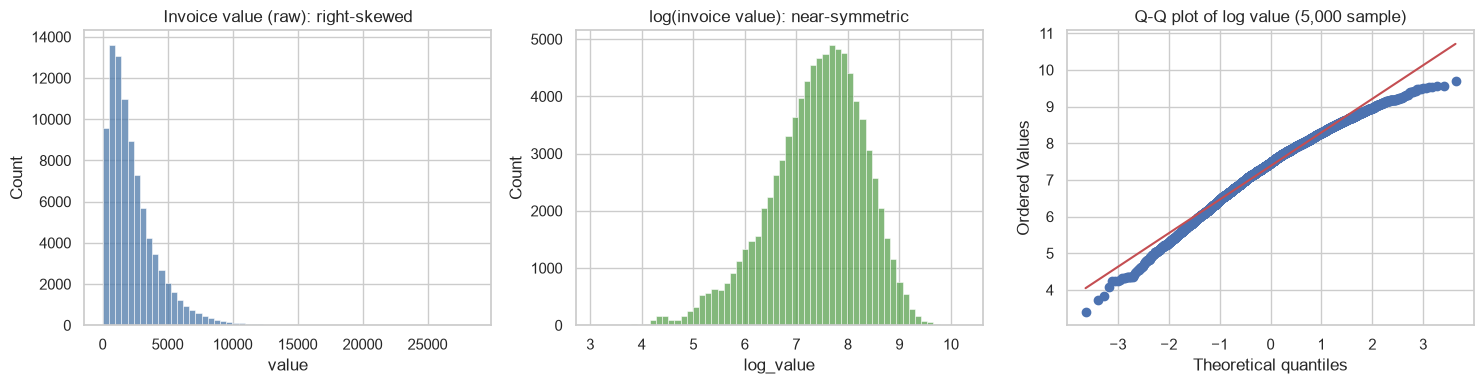

Levene test for equal variances: p = 5.42e-67  -> variances differ, so use Welch (does not assume equal variance)


In [4]:
a = inv.loc[inv.is_mpesa, "value"];  b = inv.loc[~inv.is_mpesa, "value"]
print(f"M-Pesa: n={len(a):,}, mean={a.mean():,.0f}, median={a.median():,.0f}")
print(f"Other : n={len(b):,}, mean={b.mean():,.0f}, median={b.median():,.0f}")
print(f"Skewness of invoice value: raw={stats.skew(inv['value']):.2f}, log={stats.skew(inv['log_value']):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(inv["value"], bins=60, ax=ax[0], color="#4C78A8"); ax[0].set_title("Invoice value (raw): right-skewed")
sns.histplot(inv["log_value"], bins=60, ax=ax[1], color="#59A14F"); ax[1].set_title("log(invoice value): near-symmetric")
stats.probplot(inv["log_value"].sample(5000, random_state=1), plot=ax[2]); ax[2].set_title("Q-Q plot of log value (5,000 sample)")
plt.tight_layout(); plt.show()

lev = stats.levene(a, b)
print(f"Levene test for equal variances: p = {lev.pvalue:.3g}  -> variances differ, so use Welch (does not assume equal variance)")

In [5]:
# Compare basket values using a Welch t-test on the log scale.

# Convert invoice values to their natural logarithms
la, lb = np.log(a), np.log(b)

# Perform Welch's t-test on the log-transformed values
# equal_var=False means we do not assume equal variances
w_log = stats.ttest_ind(la, lb, equal_var=False)

# Calculate the 95% confidence interval for the log-scale difference
ci_log = w_log.confidence_interval()

# Convert the log-scale difference back into a ratio
# A ratio above 1 means M-Pesa baskets have a higher geometric mean
ratio = np.exp(la.mean() - lb.mean())

# Convert the confidence interval into the same ratio scale
ratio_ci = np.exp([ci_log.low, ci_log.high])


# Perform Welch's t-test using the original invoice values in KES
# This directly compares the average basket values between the groups
w_raw = stats.ttest_ind(a, b, equal_var=False)

# Calculate the 95% confidence interval for the difference in mean basket values
ci_raw = w_raw.confidence_interval()


# Perform the Mann-Whitney U test
# This compares the ranks of invoice values between the two groups
mw = stats.mannwhitneyu(a, b, alternative="two-sided")

# Calculate the probability that a randomly selected M-Pesa basket
# is larger than a randomly selected basket from another payment method
ps = prob_superiority(a, b)

# Calculate Cohen's d to measure the standardized difference
# between the average basket values of the two groups
d = cohens_d(a, b)


# Display the results of the statistical tests

# Difference in average basket value in KES, confidence interval, and p-value
print(
    f"Welch t-test (raw KES): difference in mean = "
    f"{a.mean()-b.mean():,.0f} KES, "
    f"95% CI [{ci_raw.low:,.0f}, {ci_raw.high:,.0f}], "
    f"p = {w_raw.pvalue:.3g}"
)

# Relative difference between the groups using the log-transformed values
print(
    f"Welch t-test (log scale): M-Pesa baskets are "
    f"{ratio:.3f}x other baskets "
    f"(95% CI {ratio_ci[0]:.3f} to {ratio_ci[1]:.3f}), "
    f"p = {w_log.pvalue:.3g}"
)

# Display the Mann-Whitney test result and probability of superiority
print(
    f"Mann-Whitney U: p = {mw.pvalue:.3g}; "
    f"probability a random M-Pesa basket is larger = {ps:.3f}"
)

# Display the standardized difference between the two groups
print(f"Cohen's d = {d:.3f}")


# Save the main test results in the summary list for later reporting
log_result(
    "Welch t-test + Mann-Whitney",
    "Do M-Pesa baskets differ in value from other payment methods?",
    w_raw.pvalue,
    f"d = {d:.2f}; M-Pesa/other = {ratio:.2f}x",
    f"[{ci_raw.low:,.0f}, {ci_raw.high:,.0f}] KES",
    "Reject H0" if w_raw.pvalue < ALPHA else "Fail to reject H0"
)

Welch t-test (raw KES): difference in mean = 393 KES, 95% CI [367, 418], p = 6.71e-204
Welch t-test (log scale): M-Pesa baskets are 1.229x other baskets (95% CI 1.214 to 1.244), p = 3.03e-239
Mann-Whitney U: p = 2.79e-245; probability a random M-Pesa basket is larger = 0.565
Cohen's d = 0.204


In [6]:
# Robustness: is the M-Pesa gap just because M-Pesa users are more often loyalty members, or shop in bigger stores?
known = inv.dropna(subset=["loyalty_member"]).copy()
known["loyalty_member"] = known["loyalty_member"].astype(int)
m = smf.ols("log_value ~ is_mpesa + loyalty_member + C(store_type) + on_promo", data=known.assign(is_mpesa=known.is_mpesa.astype(int), on_promo=known.on_promo.astype(int))).fit(cov_type="HC3")
coef = m.params["is_mpesa"]; lo, hi = m.conf_int().loc["is_mpesa"]
print(f"After adjusting for loyalty, store type and promotion: M-Pesa baskets are {100*(np.exp(coef)-1):.1f}% larger "
      f"(95% CI {100*(np.exp(lo)-1):.1f}% to {100*(np.exp(hi)-1):.1f}%), p = {m.pvalues['is_mpesa']:.3g}")

After adjusting for loyalty, store type and promotion: M-Pesa baskets are 22.4% larger (95% CI 20.9% to 24.0%), p = 9.32e-223


**Conclusion (Test 1).** M-Pesa baskets averaged KES 2,472 compared with KES 2,079 for other payment methods, representing a statistically significant difference of approximately 23%. The difference remained after adjustment for loyalty membership, store type, and promotions, suggesting a consistent association, although not a causal relationship.

## Test 2: Did promotions change sales?
Promotions are not randomly assigned: they run at particular times of year (Black Friday in November, Easter in April), and revenue already varies by weekday, month and trend. A plain "promo days vs other days" comparison would mix the promotion effect with those patterns, so I do it in three steps: naive, calendar-adjusted, then a within-promotion comparison that uses un-promoted categories as a control.

**2a. Total daily revenue on promotion days vs other days**
- H₀: promotion days have the same mean daily revenue as non-promotion days.
- H₁: they differ.

**Unit:** one calendar day.

Promo days: 111, mean daily revenue 174,330 | Non-promo days: 1258, mean 146,781
Shapiro-Wilk p (promo days): 0.0158 | (non-promo, 500 sample): 2.45e-09
NAIVE comparison: difference = 27,549 KES/day, 95% CI [18,772, 36,326], Welch p = 6.94e-09, Mann-Whitney p = 5.28e-10


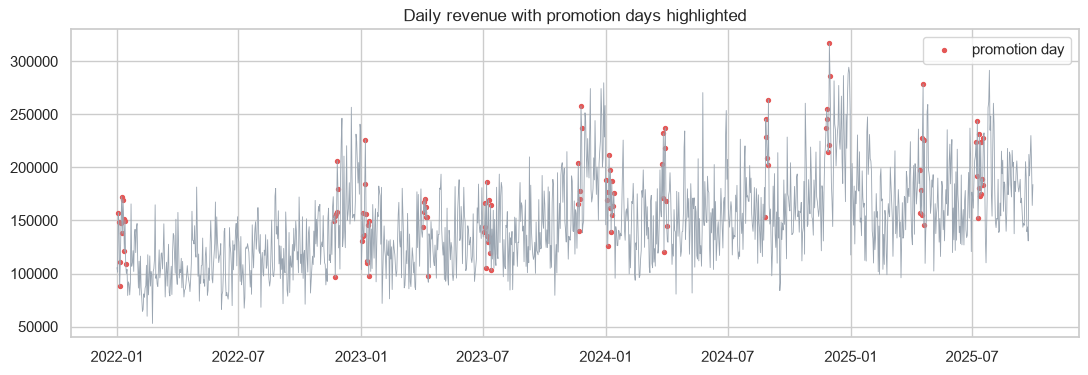

In [7]:
# Daily revenue (all sales lines), flagged for whether ANY promotion was running that day
daily = sales.groupby("transaction_date")["line_total_kes"].sum().rename("revenue").reset_index()
daily["promo_day"] = False
for _, r in promos.iterrows():
    daily.loc[daily.transaction_date.between(r.start_date, r.end_date), "promo_day"] = True
daily["dow"] = daily.transaction_date.dt.day_name()
daily["month"] = daily.transaction_date.dt.month
daily["year"] = daily.transaction_date.dt.year
daily["trend"] = (daily.transaction_date - daily.transaction_date.min()).dt.days
daily["log_rev"] = np.log(daily["revenue"])

p_days = daily.loc[daily.promo_day, "revenue"]; n_days = daily.loc[~daily.promo_day, "revenue"]
print(f"Promo days: {len(p_days)}, mean daily revenue {p_days.mean():,.0f} | Non-promo days: {len(n_days)}, mean {n_days.mean():,.0f}")
print("Shapiro-Wilk p (promo days):", f"{stats.shapiro(p_days).pvalue:.3g}", "| (non-promo, 500 sample):", f"{stats.shapiro(n_days.sample(500, random_state=1)).pvalue:.3g}")

naive = stats.ttest_ind(p_days, n_days, equal_var=False); nci = naive.confidence_interval()
mw2 = stats.mannwhitneyu(p_days, n_days)
print(f"NAIVE comparison: difference = {p_days.mean()-n_days.mean():,.0f} KES/day, 95% CI [{nci.low:,.0f}, {nci.high:,.0f}], Welch p = {naive.pvalue:.3g}, Mann-Whitney p = {mw2.pvalue:.3g}")

# Why naive is not enough: revenue has a trend, a weekly cycle and a seasonal cycle, and promotions sit in particular months
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.transaction_date, daily.revenue, lw=0.6, color="#9aa5b1")
ax.scatter(daily.loc[daily.promo_day, "transaction_date"], daily.loc[daily.promo_day, "revenue"], s=8, color="#E45756", label="promotion day")
ax.set_title("Daily revenue with promotion days highlighted"); ax.legend(); plt.show()

In [8]:
# Regression adjustment: compare promo days with similar days (same weekday, month and year, plus a trend)
# HAC (Newey-West) standard errors allow for day-to-day autocorrelation.
reg = smf.ols("log_rev ~ promo_day + C(dow) + C(month) + C(year) + trend", data=daily.assign(promo_day=daily.promo_day.astype(int))).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
coef = reg.params["promo_day"]; lo, hi = reg.conf_int().loc["promo_day"]
print(f"Adjusted promo effect on daily revenue: {100*(np.exp(coef)-1):+.1f}% (95% CI {100*(np.exp(lo)-1):+.1f}% to {100*(np.exp(hi)-1):+.1f}%), p = {reg.pvalues['promo_day']:.3g}")
resid = reg.resid
print(f"Durbin-Watson of residuals = {sm.stats.durbin_watson(resid):.2f}  (2 = no autocorrelation; HAC errors used regardless)")
print(f"Residual skewness = {stats.skew(resid):.2f}  (close to 0 = residuals roughly symmetric)")
# Split the effect: store-wide promotions (Black Friday, target = All) vs single-category promotions
daily["promo_all"] = 0; daily["promo_cat"] = 0
for _, r in promos.iterrows():
    col = "promo_all" if r.category_targeted == "All" else "promo_cat"
    daily.loc[daily.transaction_date.between(r.start_date, r.end_date), col] = 1
reg2 = smf.ols("log_rev ~ promo_all + promo_cat + C(dow) + C(month) + C(year) + trend", data=daily).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
for k, lab in (("promo_all", "Store-wide promotions (Black Friday)"), ("promo_cat", "Single-category promotions")):
    lo2, hi2 = reg2.conf_int().loc[k]
    print(f"{lab}: {100*(np.exp(reg2.params[k])-1):+.1f}% daily revenue (95% CI {100*(np.exp(lo2)-1):+.1f}% to {100*(np.exp(hi2)-1):+.1f}%), p = {reg2.pvalues[k]:.3g}")
log_result("OLS with calendar controls (HAC)", "Do promotion days have higher total daily revenue than comparable days?",
           reg.pvalues["promo_day"], f"{100*(np.exp(coef)-1):+.1f}% daily revenue",
           f"[{100*(np.exp(lo)-1):+.1f}%, {100*(np.exp(hi)-1):+.1f}%]", "Reject H0" if reg.pvalues["promo_day"] < ALPHA else "Fail to reject H0")

Adjusted promo effect on daily revenue: +20.0% (95% CI +15.5% to +24.6%), p = 4.76e-21
Durbin-Watson of residuals = 1.70  (2 = no autocorrelation; HAC errors used regardless)
Residual skewness = -0.22  (close to 0 = residuals roughly symmetric)
Store-wide promotions (Black Friday): +23.0% daily revenue (95% CI +14.3% to +32.3%), p = 3.17e-08
Single-category promotions: +19.3% daily revenue (95% CI +14.2% to +24.6%), p = 2.65e-15


**2b. Did the *promoted category* sell more than un-promoted categories?** If promotions work by discounting a category, that category should rise more than the others during the promotion.

In [9]:
# Promotion-by-promotion test on the category each promotion targeted
# Change = mean daily revenue of targeted category during the promotion vs the 28 days before it.
# Difference-in-differences: subtract the same change in categories that were NOT promoted (controls for season).
cat_daily = (sales.merge(products[["product_id", "category"]], on="product_id")
             .groupby(["transaction_date", "category"])["line_total_kes"].sum().reset_index())

rows = []
for _, r in promos.iterrows():
    pre = pd.date_range(r.start_date - pd.Timedelta(days=28), r.start_date - pd.Timedelta(days=1))
    dur = pd.date_range(r.start_date, r.end_date)
    pre_days_available = (pre >= cat_daily.transaction_date.min()).sum()
    if pre_days_available < 14:      # PR01 starts 2 days into the data: no usable baseline, so it is excluded
        print(f"{r.promo_id} excluded: only {pre_days_available} pre-promotion days in the data")
        continue
    def mean_rev(cats, days):
        s = cat_daily[cat_daily.category.isin(cats) & cat_daily.transaction_date.isin(days)]
        return s.groupby("transaction_date")["line_total_kes"].sum().reindex(days).mean()   # days outside the data are ignored
    target = products.category.unique() if r.category_targeted == "All" else [r.category_targeted]
    lift_t = mean_rev(target, dur) / mean_rev(target, pre) - 1
    others = [c for c in products.category.unique() if c not in target]
    lift_c = mean_rev(others, dur) / mean_rev(others, pre) - 1 if others else np.nan
    rows.append({"promo_id": r.promo_id, "promo": r.promo_name, "targets": r.category_targeted, "discount_pct": r.discount_pct,
                 "lift_targeted_pct": 100 * lift_t, "lift_other_cats_pct": 100 * lift_c if others else np.nan,
                 "did_pct_points": 100 * (lift_t - lift_c) if others else np.nan})
lifts = pd.DataFrame(rows)
display(lifts.round(1))

PR01 excluded: only 2 pre-promotion days in the data


,promo_id,promo,targets,discount_pct,lift_targeted_pct,lift_other_cats_pct,did_pct_points
0,PR02,Black Friday,All,25,17.6000,NaN,NaN
1,PR03,Back-to-School,Household,12,-11.5000,-19.9000,8.4000
2,PR04,Easter Offer,Food Staples,10,40.6000,17.1000,23.6000
3,PR05,Mid-Year Sale,Personal Care,15,-9.2000,8.6000,-17.8000
4,PR06,Black Friday,All,30,22.0000,NaN,NaN
5,PR07,Back-to-School,Snacks,12,-5.3000,-19.7000,14.4000
6,PR08,Easter Offer,Dairy,10,24.5000,29.9000,-5.4000
7,PR09,Month-End Mega,Beverages,8,54.9000,32.9000,22.0000
8,PR10,Black Friday,All,25,47.5000,NaN,NaN
9,PR11,Easter Offer,Food Staples,10,17.6000,13.2000,4.4000


n promotions with control group = 8
Shapiro-Wilk on the differences: p = 0.732  (n is small, so also run a rank test)
Mean extra lift vs un-promoted categories = +5.5 percentage points, 95% CI [-6.6, +17.6]
One-sample t-test p = 0.3172 | Wilcoxon signed-rank p = 0.3828 | promotions with positive lift: 5 of 8


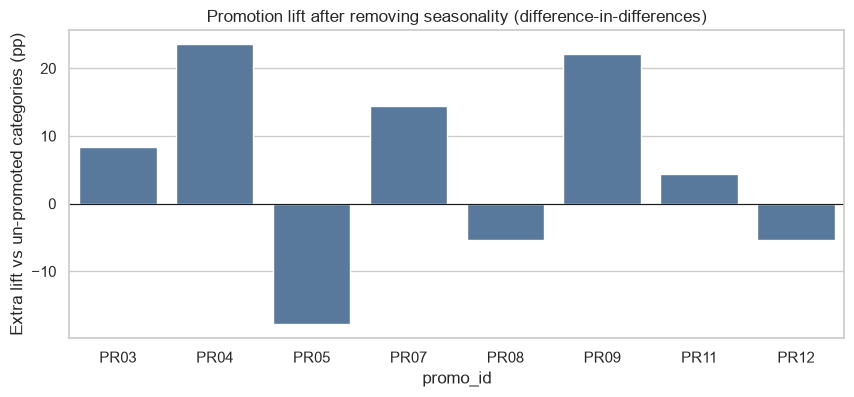

Pooled day-level diff-in-diff: promoted categories sold +5.1% more than un-promoted ones during the promotion (95% CI -5.9% to +17.3%), p = 0.377


In [10]:
# Paired comparison on the promotions that have an un-promoted control group (the three Black Friday promos target "All")
did = lifts["did_pct_points"].dropna()
print(f"n promotions with control group = {len(did)}")
print(f"Shapiro-Wilk on the differences: p = {stats.shapiro(did).pvalue:.3f}  (n is small, so also run a rank test)")
tt = stats.ttest_1samp(did, 0); tci = tt.confidence_interval()
wx = stats.wilcoxon(did)
print(f"Mean extra lift vs un-promoted categories = {did.mean():+.1f} percentage points, 95% CI [{tci.low:+.1f}, {tci.high:+.1f}]")
print(f"One-sample t-test p = {tt.pvalue:.4f} | Wilcoxon signed-rank p = {wx.pvalue:.4f} | promotions with positive lift: {(did>0).sum()} of {len(did)}")

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=lifts.dropna(subset=["did_pct_points"]), x="promo_id", y="did_pct_points", ax=ax, color="#4C78A8")
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("Extra lift vs un-promoted categories (pp)")
ax.set_title("Promotion lift after removing seasonality (difference-in-differences)"); plt.show()
# Pooled day-level version (more power): log revenue ~ promoted-group x during-promotion, with promotion fixed effects
panel = []
for _, r in promos.iterrows():
    if r.category_targeted == "All" or r.promo_id not in set(lifts.promo_id):
        continue
    days = pd.date_range(r.start_date - pd.Timedelta(days=28), r.end_date)
    for grp, cats in (("targeted", [r.category_targeted]), ("other", [c for c in products.category.unique() if c != r.category_targeted])):
        s = cat_daily[cat_daily.category.isin(cats) & cat_daily.transaction_date.isin(days)].groupby("transaction_date")["line_total_kes"].sum().reset_index()
        s["promo_id"], s["targeted"] = r.promo_id, int(grp == "targeted")
        s["during"] = (s.transaction_date >= r.start_date).astype(int)
        panel.append(s)
panel = pd.concat(panel); panel["log_rev"] = np.log(panel["line_total_kes"])
did_m = smf.ols("log_rev ~ targeted * during + C(promo_id):targeted + C(promo_id)", data=panel).fit(cov_type="HC3")
b = did_m.params["targeted:during"]; blo, bhi = did_m.conf_int().loc["targeted:during"]
print(f"Pooled day-level diff-in-diff: promoted categories sold {100*(np.exp(b)-1):+.1f}% more than un-promoted ones during the promotion "
      f"(95% CI {100*(np.exp(blo)-1):+.1f}% to {100*(np.exp(bhi)-1):+.1f}%), p = {did_m.pvalues['targeted:during']:.3g}")
log_result("Pooled diff-in-diff regression", "Does a promotion lift the promoted category beyond what un-promoted categories did?",
           did_m.pvalues["targeted:during"], f"{100*(np.exp(b)-1):+.1f}% extra revenue", f"[{100*(np.exp(blo)-1):+.1f}%, {100*(np.exp(bhi)-1):+.1f}%]",
           "Reject H0" if did_m.pvalues["targeted:during"] < ALPHA else "Fail to reject H0")
log_result("Paired t-test + Wilcoxon (diff-in-diff)", "Do promoted categories sell more during a promotion than un-promoted categories do?",
           tt.pvalue, f"{did.mean():+.1f} pp mean extra lift", f"[{tci.low:+.1f}, {tci.high:+.1f}] pp",
           "Reject H0" if tt.pvalue < ALPHA else "Fail to reject H0")

**Conclusion (Test 2b).** There was no statistically significant evidence that promoted categories experienced greater sales growth than unpromoted categories, despite an average additional increase of about 5 percentage points. However, with only eight promotions analyzed, the test had limited power, so the findings do not rule out a potential promotional effect.

## Test 3: Do loyalty members spend more?
**Unit:** one registered customer (their average basket value). Using customers rather than invoices avoids letting heavy shoppers count many times.
- H₀: members and non-members have the same mean average basket.
- H₁: they differ.

Members: n=1,632, mean avg basket=2,477 | Non-members: n=2,973, mean=2,218
Skewness: members=3.38, non-members=2.57; Levene p = 0.596
Welch: difference = 259 KES, 95% CI [203, 315], p = 1.44e-19
Mann-Whitney p = 9.21e-37 | Cohen's d = 0.28


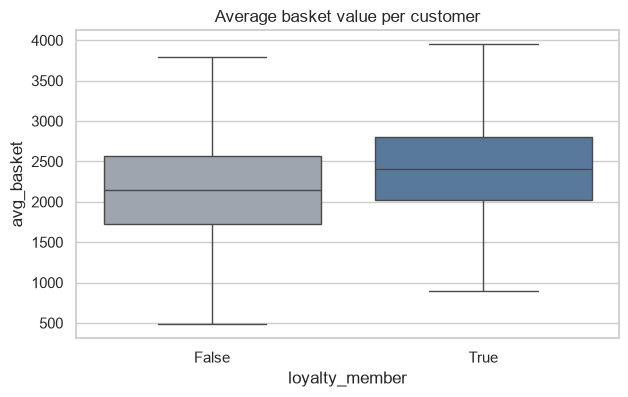

In [11]:
# Unit = customer: each registered customer's average basket value (avoids counting heavy shoppers many times)
cust = (inv.dropna(subset=["loyalty_member"]).groupby(["customer_id", "loyalty_member"])
        .agg(avg_basket=("value", "mean"), n_invoices=("invoice_no", "count")).reset_index())
yes = cust.loc[cust.loyalty_member == True, "avg_basket"]; no = cust.loc[cust.loyalty_member == False, "avg_basket"]
print(f"Members: n={len(yes):,}, mean avg basket={yes.mean():,.0f} | Non-members: n={len(no):,}, mean={no.mean():,.0f}")
print(f"Skewness: members={stats.skew(yes):.2f}, non-members={stats.skew(no):.2f}; Levene p = {stats.levene(yes, no).pvalue:.3g}")

w = stats.ttest_ind(yes, no, equal_var=False); ci = w.confidence_interval()
mw = stats.mannwhitneyu(yes, no); d = cohens_d(yes, no)
print(f"Welch: difference = {yes.mean()-no.mean():,.0f} KES, 95% CI [{ci.low:,.0f}, {ci.high:,.0f}], p = {w.pvalue:.3g}")
print(f"Mann-Whitney p = {mw.pvalue:.3g} | Cohen's d = {d:.2f}")
fig, ax = plt.subplots(figsize=(7, 4)); sns.boxplot(data=cust, x="loyalty_member", y="avg_basket", showfliers=False, ax=ax, palette=["#9aa5b1", "#4C78A8"])
ax.set_title("Average basket value per customer"); plt.show()
log_result("Welch t-test + Mann-Whitney", "Do loyalty members have larger average baskets than non-members?",
           w.pvalue, f"d = {d:.2f}", f"[{ci.low:,.0f}, {ci.high:,.0f}] KES", "Reject H0" if w.pvalue < ALPHA else "Fail to reject H0")

**Conclusion (Test 3).** Loyalty members had significantly higher average basket values than non-members (KES 2,477 versus KES 2,218), spending approximately 12% more per visit. However, the effect was small, and the difference does not establish that loyalty programme membership causes higher spending.

## Test 4: Does payday change shopping behaviour?
**Unit:** invoice for basket value, calendar day for traffic.
- H₀: payday-period baskets have the same mean value as other baskets (and the same invoices per day).
- H₁: they differ.

In [12]:
# Payday period vs other days: basket value and daily revenue
pa = inv.loc[inv.payday, "value"]; pb = inv.loc[~inv.payday, "value"]
w = stats.ttest_ind(pa, pb, equal_var=False); ci = w.confidence_interval(); mw = stats.mannwhitneyu(pa, pb)
print(f"Basket value: payday mean {pa.mean():,.0f} vs other {pb.mean():,.0f}; difference {pa.mean()-pb.mean():,.0f} KES, 95% CI [{ci.low:,.0f}, {ci.high:,.0f}], p = {w.pvalue:.3g} (MW p = {mw.pvalue:.3g})")

pay_daily = inv.assign(pd_=inv.payday).groupby("date").agg(rev=("value", "sum"), n=("invoice_no", "count"), pd_=("pd_", "max")).reset_index()
da = pay_daily.loc[pay_daily.pd_, "n"]; db = pay_daily.loc[~pay_daily.pd_, "n"]
w2 = stats.ttest_ind(da, db, equal_var=False); ci2 = w2.confidence_interval()
print(f"Invoices per day: payday {da.mean():.1f} vs other {db.mean():.1f}; difference {da.mean()-db.mean():+.1f}, 95% CI [{ci2.low:+.1f}, {ci2.high:+.1f}], p = {w2.pvalue:.3g}")
log_result("Welch t-test", "Is basket value different in the payday period?", w.pvalue, f"d = {cohens_d(pa, pb):.3f}",
           f"[{ci.low:,.0f}, {ci.high:,.0f}] KES", "Reject H0" if w.pvalue < ALPHA else "Fail to reject H0")

Basket value: payday mean 2,288 vs other 2,309; difference -22 KES, 95% CI [-51, 8], p = 0.145 (MW p = 0.0726)
Invoices per day: payday 76.6 vs other 61.5; difference +15.2, 95% CI [+13.0, +17.3], p = 7.6e-36


**Conclusion (Test 4).** Payday periods did not significantly affect average basket value, but they were associated with approximately 15 additional invoices per day (76.6 versus 61.5). This suggests payday increases sales mainly through higher customer traffic rather than larger baskets, making staffing and stock planning particularly important.

## Test 5: Do store types differ in basket value?
**Unit:** invoice (log value). **Groups:** Kiosk, Mini-mart, Supermarket.
- H₀: all three store types have the same mean log basket value.
- H₁: at least one differs.

In [13]:
groups = [g["log_value"].to_numpy() for _, g in inv.groupby("store_type")]
print(inv.groupby("store_type")["value"].agg(["count", "mean", "median"]).round(0))
print(f"Levene (equal variance across store types): p = {stats.levene(*groups).pvalue:.3g}")
f = stats.f_oneway(*groups); kw = stats.kruskal(*groups)
# eta-squared = share of variation in log basket value explained by store type
grand = inv["log_value"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups); ss_total = ((inv["log_value"] - grand) ** 2).sum()
eta2 = ss_between / ss_total
print(f"One-way ANOVA (log value): F = {f.statistic:.2f}, p = {f.pvalue:.3g} | Kruskal-Wallis p = {kw.pvalue:.3g} | eta-squared = {eta2:.5f}")
tk = pairwise_tukeyhsd(inv["log_value"], inv["store_type"], alpha=ALPHA)
print(tk.summary())
log_result("One-way ANOVA + Kruskal-Wallis + Tukey", "Do basket values differ across store types?", f.pvalue,
           f"eta-squared = {eta2:.4f}", "see Tukey table", "Reject H0" if f.pvalue < ALPHA else "Fail to reject H0")

             count       mean     median
store_type                              
Kiosk        10455 2,323.0000 1,805.0000
Mini-mart    31725 2,324.0000 1,786.0000
Supermarket  46363 2,286.0000 1,771.0000
Levene (equal variance across store types): p = 0.184
One-way ANOVA (log value): F = 1.74, p = 0.175 | Kruskal-Wallis p = 0.18 | eta-squared = 0.00004
    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1     group2   meandiff p-adj   lower  upper  reject
-----------------------------------------------------------
    Kiosk   Mini-mart  -0.0073 0.7616 -0.0315  0.017  False
    Kiosk Supermarket  -0.0161 0.2346 -0.0394 0.0071  False
Mini-mart Supermarket  -0.0089 0.3795 -0.0245 0.0068  False
-----------------------------------------------------------


## Test 6: Is payment method linked to sales channel?
**Unit:** invoice. Both variables are categorical, so a chi-square test of independence applies.
- H₀: payment method and channel are independent.
- H₁: they are associated.

channel       In-store  Online  Pickup
payment                               
Airtel Money      3269     478     302
Card              6553    1015     669
Cash             23289       0    2317
M-Pesa           37679    9223    3749
Smallest expected count = 321.8 (rule of thumb: all >= 5, so the chi-square approximation is valid)
Chi-square(6) = 5303.71, p = 0, Cramer's V = 0.173


channel,In-store,Online,Pickup
payment,,,
Airtel Money,80.7000,11.8000,7.5000
Card,79.6000,12.3000,8.1000
Cash,91.0000,0.0000,9.0000
M-Pesa,74.4000,18.2000,7.4000


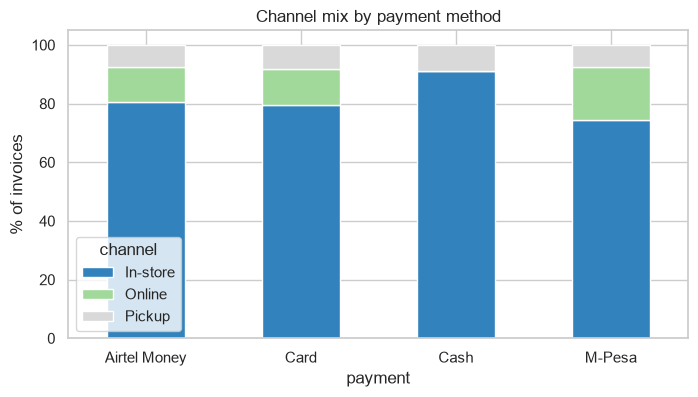

In [14]:
ct = pd.crosstab(inv["payment"], inv["channel"])
print(ct)
chi2, p, dof, exp = stats.chi2_contingency(ct)
print(f"Smallest expected count = {exp.min():.1f} (rule of thumb: all >= 5, so the chi-square approximation is valid)")
n = ct.to_numpy().sum(); v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print(f"Chi-square({dof}) = {chi2:.2f}, p = {p:.3g}, Cramer's V = {v:.3f}")
share = pd.crosstab(inv["payment"], inv["channel"], normalize="index").mul(100).round(1)
display(share)
share.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="tab20c"); plt.ylabel("% of invoices"); plt.title("Channel mix by payment method"); plt.xticks(rotation=0); plt.show()
log_result("Chi-square test of independence", "Is payment method associated with sales channel?", p, f"Cramer's V = {v:.3f}", "n/a",
           "Reject H0" if p < ALPHA else "Fail to reject H0")

## Test 7: Are promotional sales returned more often?
**Unit:** transaction line. Proportions are compared with a two-proportion z-test, with Wilson confidence intervals for each rate.
- H₀: return rate is the same on promotion lines and other lines.
- H₁: the return rates differ.

In [15]:
# Return rate (share of lines that are returns): promotion lines vs non-promotion lines
g = tx.groupby("on_promo")["is_return"].agg(["sum", "count"])
x = g["sum"].to_numpy(); nobs = g["count"].to_numpy()
rates = x / nobs
for flag, r, xi, ni in zip(g.index, rates, x, nobs):
    lo, hi = proportion_confint(xi, ni, method="wilson")
    print(f"on_promo={flag}: {xi:,} returns of {ni:,} lines = {100*r:.2f}% (95% Wilson CI {100*lo:.2f}% to {100*hi:.2f}%)")
z, p = proportions_ztest(x, nobs)
diff = rates[1] - rates[0]; se = np.sqrt(rates[0]*(1-rates[0])/nobs[0] + rates[1]*(1-rates[1])/nobs[1])
print(f"Two-proportion z-test: difference = {100*diff:+.2f} pp, 95% CI [{100*(diff-1.96*se):+.2f}, {100*(diff+1.96*se):+.2f}] pp, p = {p:.3f}")
log_result("Two-proportion z-test", "Are promotional lines returned more often?", p, f"{100*diff:+.2f} pp",
           f"[{100*(diff-1.96*se):+.2f}, {100*(diff+1.96*se):+.2f}] pp", "Reject H0" if p < ALPHA else "Fail to reject H0")

on_promo=False: 1,247 returns of 240,726 lines = 0.52% (95% Wilson CI 0.49% to 0.55%)
on_promo=True: 45 returns of 9,274 lines = 0.49% (95% Wilson CI 0.36% to 0.65%)
Two-proportion z-test: difference = -0.03 pp, 95% CI [-0.18, +0.11] pp, p = 0.666


## Summary of all tests

In [16]:
summary = pd.DataFrame(RESULTS)
summary["p-value"] = summary["p-value"].map(lambda p: "< 0.0001" if p < 1e-4 else f"{p:.4f}")
summary.index = range(1, len(summary) + 1)
summary.to_csv("../data/clean/statistical_tests_summary.csv", index_label="#")
summary

,Test,Question,p-value,Effect size,95% CI,Decision (alpha = 0.05)
1,Welch t-test + Mann-Whitney,Do M-Pesa baskets differ in value from other p...,< 0.0001,d = 0.20; M-Pesa/other = 1.23x,"[367, 418] KES",Reject H0
2,OLS with calendar controls (HAC),Do promotion days have higher total daily reve...,< 0.0001,+20.0% daily revenue,"[+15.5%, +24.6%]",Reject H0
3,Pooled diff-in-diff regression,Does a promotion lift the promoted category be...,0.3772,+5.1% extra revenue,"[-5.9%, +17.3%]",Fail to reject H0
4,Paired t-test + Wilcoxon (diff-in-diff),Do promoted categories sell more during a prom...,0.3172,+5.5 pp mean extra lift,"[-6.6, +17.6] pp",Fail to reject H0
5,Welch t-test + Mann-Whitney,Do loyalty members have larger average baskets...,< 0.0001,d = 0.28,"[203, 315] KES",Reject H0
6,Welch t-test,Is basket value different in the payday period?,0.1454,d = -0.011,"[-51, 8] KES",Fail to reject H0
7,One-way ANOVA + Kruskal-Wallis + Tukey,Do basket values differ across store types?,0.1748,eta-squared = 0.0000,see Tukey table,Fail to reject H0
8,Chi-square test of independence,Is payment method associated with sales channel?,< 0.0001,Cramer's V = 0.173,n/a,Reject H0
9,Two-proportion z-test,Are promotional lines returned more often?,0.6656,-0.03 pp,"[-0.18, +0.11] pp",Fail to reject H0


## The five findings that matter most
1. **M-Pesa customers spend about 23% more per basket** (KES 393, CI 367 to 418), and the gap survives adjustment for loyalty, store type and promotions. The effect size is small to moderate (d = 0.20).
2. **Promotion days have about 20% higher revenue** than comparable days (CI 15.5% to 24.6%), but the promoted category did not clearly outperform un-promoted ones (+5 pp, CI includes 0). The lift looks like a store-wide traffic effect.
3. **Loyalty members spend about KES 259 more per basket** (CI 203 to 315), roughly 12%.
4. **Payday changes traffic, not basket size**: about 15 more invoices per day, with no change in basket value.
5. **Store type does not affect basket value** (p = 0.18), and **promotions do not raise return rates** (0.49% vs 0.52%).

## Limitations
- The data is synthetic, built with these effects in mind, so the *size* of an effect should not be generalised to real Kenyan retail. The *method* is what carries over.
- The data is observational. Promotions, payment choice and loyalty were not randomly assigned, so all conclusions are about association.